In [1]:
import pandas as pd
import numpy as np
import ast
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.preprocessing import MultiLabelBinarizer, StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import seaborn as sns
from pandas.plotting import parallel_coordinates
from sklearn.cluster import KMeans



In [2]:
# ============================================================
# 2. ЗАГРУЗКА ДАННЫХ
# ============================================================
df = pd.read_csv('final_cocktails.csv')

# Убираем первый служебный столбец (индекс из CSV)
if df.columns[0].startswith('Unnamed') or df.columns[0] == '':
    df = df.drop(columns=df.columns[0])

print("Размер датасета:", df.shape)
print("Столбцы:", df.columns.tolist())
df.head(3)

Размер датасета: (425, 10)
Столбцы: ['id', 'name', 'alcoholic', 'category', 'glassType', 'instructions', 'drinkThumbnail', 'ingredients', 'ingredientMeasures', 'text']


,id,name,alcoholic,category,glassType,instructions,drinkThumbnail,ingredients,ingredientMeasures,text
0,0,A1,Alcoholic,Cocktail,Cocktail glass,"Pour all ingredients into a cocktail shaker, m...",https://www.thecocktaildb.com/images/media/dri...,"['Gin', 'Grand Marnier', 'Lemon Juice', 'Grena...","['1 3/4 shot ', '1 Shot ', '1/4 Shot', '1/8 Sh...",question Generate a cocktail with Gin Grand Ma...
1,1,ABC,Alcoholic,Shot,Shot glass,Layered in a shot glass.,https://www.thecocktaildb.com/images/media/dri...,"['Amaretto', 'Baileys irish cream', 'Cognac']","['1/3 ', '1/3 ', '1/3 ']",question Generate a cocktail with Amaretto Bai...
2,2,Ace,Alcoholic,Cocktail,Martini Glass,Shake all the ingredients in a cocktail shaker...,https://www.thecocktaildb.com/images/media/dri...,"['Gin', 'Grenadine', 'Heavy cream', 'Milk', 'E...","['2 shots ', '1/2 shot ', '1/2 shot ', '1/2 sh...",question Generate a cocktail with Gin Grenadin...


In [3]:
# ============================================================
# 3. ПРЕДОБРАБОТКА: ПАРСИНГ ИНГРЕДИЕНТОВ
# ============================================================
# Столбцы ingredients и ingredientMeasures хранятся как строки-списки
# (например "['Gin', 'Lemon Juice']"). Преобразуем их в реальные списки.
def parse_list(x):
    try:
        return ast.literal_eval(x) if isinstance(x, str) else []
    except (ValueError, SyntaxError):
        return []

df['ingredients_list'] = df['ingredients'].apply(parse_list)

# Убираем пустые ингредиенты и лишние пробелы, приводим к нижнему регистру
df['ingredients_list'] = df['ingredients_list'].apply(
    lambda lst: [str(i).strip().lower() for i in lst if str(i).strip()]
)

# Оставляем только строки, где есть хотя бы один ингредиент
df = df[df['ingredients_list'].map(len) > 0].reset_index(drop=True)

print("Количество напитков после очистки:", len(df))
print("\nПример ингредиентов:")
print(df[['name', 'ingredients_list']].head())

Количество напитков после очистки: 425

Пример ингредиентов:
   name                                ingredients_list
0    A1    [gin, grand marnier, lemon juice, grenadine]
1   ABC         [amaretto, baileys irish cream, cognac]
2   Ace  [gin, grenadine, heavy cream, milk, egg white]
3  ACID                    [151 proof rum, wild turkey]
4  Adam              [dark rum, lemon juice, grenadine]


In [4]:
# ============================================================
# 4. ФОРМИРОВАНИЕ МАТРИЦЫ ПРИЗНАКОВ (one-hot по ингредиентам)
# ============================================================
mlb = MultiLabelBinarizer()
X_ing = mlb.fit_transform(df['ingredients_list'])

print("Размер матрицы ингредиентов:", X_ing.shape)
print("Уникальных ингредиентов:", len(mlb.classes_))

Размер матрицы ингредиентов: (425, 293)
Уникальных ингредиентов: 293


In [5]:
# Дополнительные категориальные признаки: alcoholic и category
df['alcoholic_enc'] = (df['alcoholic'].str.lower() == 'alcoholic').astype(int)

# One-hot для категории напитка
cat_dummies = pd.get_dummies(df['category'], prefix='cat')

# Итоговая матрица признаков
X = np.hstack([X_ing, df[['alcoholic_enc']].values, cat_dummies.values])
print("Итоговый размер матрицы признаков:", X.shape)

Итоговый размер матрицы признаков: (425, 305)


In [6]:
# ============================================================
# 5. МАСШТАБИРОВАНИЕ
# ============================================================
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [ ]:
# ============================================================
# 7. ФИНАЛЬНАЯ КЛАСТЕРИЗАЦИЯ KMeans
# ============================================================
# Выберите k (например, 4). Можно подставить значение,
# дающее лучший silhouette на предыдущем шаге.
K_OPT = 4

kmeans = KMeans(n_clusters=K_OPT, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)

print("Распределение по кластерам:")
print(df['cluster'].value_counts().sort_index())

print("\nSilhouette Score финальной модели:",
      round(silhouette_score(X_scaled, df['cluster']), 3))

Распределение по кластерам:
cluster
0    379
1     46
Name: count, dtype: int64

Silhouette Score финальной модели: 0.125


In [9]:
# ============================================================
# 6a. ПОДБОР k С ГАРАНТИЕЙ РАЗМЕРА КЛАСТЕРА
# ============================================================
MIN_SIZE = 2          # минимально допустимый размер кластера
K_CANDIDATES = range(2, 20)

results = []
for k in K_CANDIDATES:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    sizes = np.bincount(labels, minlength=k)

    results.append({
        'k': k,
        'min_size': sizes.min(),
        'max_size': sizes.max(),
        'silhouette': silhouette_score(X_scaled, labels),
        'ok': sizes.min() >= MIN_SIZE
    })

res_df = pd.DataFrame(results)
print(res_df.round(3).to_string(index=False))

# Берём лучшее k среди тех, где условие выполнено
valid = res_df[res_df['ok']].sort_values('silhouette', ascending=False)
if len(valid) == 0:
    raise ValueError(f"Нет k, при котором все кластеры >= {MIN_SIZE}. "
                     f"Уменьшите MIN_SIZE или увеличьте данные.")

K_OPT = int(valid.iloc[0]['k'])
print(f"\nВыбрано k = {K_OPT} "
      f"(min_size={int(valid.iloc[0]['min_size'])}, "
      f"silhouette={valid.iloc[0]['silhouette']:.3f})")

kmeans = KMeans(n_clusters=K_OPT, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)

print("\nРазмеры кластеров:")
print(df['cluster'].value_counts().sort_index())

 k  min_size  max_size  silhouette    ok
 2        46       379       0.125  True
 3         1       348      -0.079 False
 4         1       362       0.072 False
 5         1       402      -0.090 False
 6         3       306      -0.062  True
 7         1       368      -0.026 False
 8         1       346      -0.076 False
 9         1       228      -0.048 False
10         1       415       0.068 False
11         1       389      -0.078 False
12         1       318      -0.005 False
13         1       325      -0.079 False
14         1       388      -0.040 False
15         1       230      -0.048 False
16         1       407       0.134 False
17         1       378      -0.119 False
18         1       299      -0.043 False
19         1       388      -0.072 False

Выбрано k = 2 (min_size=46, silhouette=0.125)

Размеры кластеров:
cluster
0    379
1     46
Name: count, dtype: int64


In [10]:
# ============================================================
# 6a. ПОДБОР k С ГАРАНТИЕЙ РАЗМЕРА КЛАСТЕРА
# ============================================================
MIN_SIZE = 2          # минимально допустимый размер кластера
K_CANDIDATES = range(2, 20)

results = []
for k in K_CANDIDATES:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    sizes = np.bincount(labels, minlength=k)

    results.append({
        'k': k,
        'min_size': sizes.min(),
        'max_size': sizes.max(),
        'silhouette': silhouette_score(X_scaled, labels),
        'ok': sizes.min() >= MIN_SIZE
    })

res_df = pd.DataFrame(results)
print(res_df.round(3).to_string(index=False))

# Берём лучшее k среди тех, где условие выполнено
valid = res_df[res_df['ok']].sort_values('silhouette', ascending=False)
if len(valid) == 0:
    raise ValueError(f"Нет k, при котором все кластеры >= {MIN_SIZE}. "
                     f"Уменьшите MIN_SIZE или увеличьте данные.")

K_OPT = int(valid.iloc[0]['k'])
print(f"\nВыбрано k = {K_OPT} "
      f"(min_size={int(valid.iloc[0]['min_size'])}, "
      f"silhouette={valid.iloc[0]['silhouette']:.3f})")

kmeans = KMeans(n_clusters=K_OPT, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)

print("\nРазмеры кластеров:")
print(df['cluster'].value_counts().sort_index())

 k  min_size  max_size  silhouette    ok
 2        46       379       0.125  True
 3         1       348      -0.079 False
 4         1       362       0.072 False
 5         1       402      -0.090 False
 6         3       306      -0.062  True
 7         1       368      -0.026 False
 8         1       346      -0.076 False
 9         1       228      -0.048 False
10         1       415       0.068 False
11         1       389      -0.078 False
12         1       318      -0.005 False
13         1       325      -0.079 False
14         1       388      -0.040 False
15         1       230      -0.048 False
16         1       407       0.134 False
17         1       378      -0.119 False
18         1       299      -0.043 False
19         1       388      -0.072 False

Выбрано k = 2 (min_size=46, silhouette=0.125)

Размеры кластеров:
cluster
0    379
1     46
Name: count, dtype: int64


In [11]:
# ============================================================
# 7. ИНТЕРПРЕТАЦИЯ КЛАСТЕРОВ: ТОП-ИНГРЕДИЕНТЫ
# ============================================================
for cl in sorted(df['cluster'].unique()):
    sub = df[df['cluster'] == cl]
    all_ing = [i for lst in sub['ingredients_list'] for i in lst]
    top = Counter(all_ing).most_common(8)
    print(f"\n=== Кластер {cl} (n={len(sub)}) ===")
    print("Топ-ингредиенты:", top)
    print("Примеры напитков:", sub['name'].head(5).tolist())
    print("Доминирующая категория:", sub['category'].mode().iloc[0])


=== Кластер 0 (n=379) ===
Топ-ингредиенты: [('gin', 82), ('vodka', 63), ('lemon juice', 47), ('orange juice', 42), ('sugar', 35), ('lemon', 35), ('grenadine', 31), ('lime juice', 31)]
Примеры напитков: ['A1', 'ABC', 'Ace', 'ACID', 'Adam']
Доминирующая категория: Ordinary Drink

=== Кластер 1 (n=46) ===
Топ-ингредиенты: [('milk', 17), ('sugar', 16), ('ice', 12), ('water', 10), ('yoghurt', 8), ('soda water', 6), ('vanilla extract', 6), ('salt', 6)]
Примеры напитков: ['Apello', 'Baby Eskimo', 'Chocolate Drink', 'Drinking Chocolate', 'Egg Cream']
Доминирующая категория: Other / Unknown


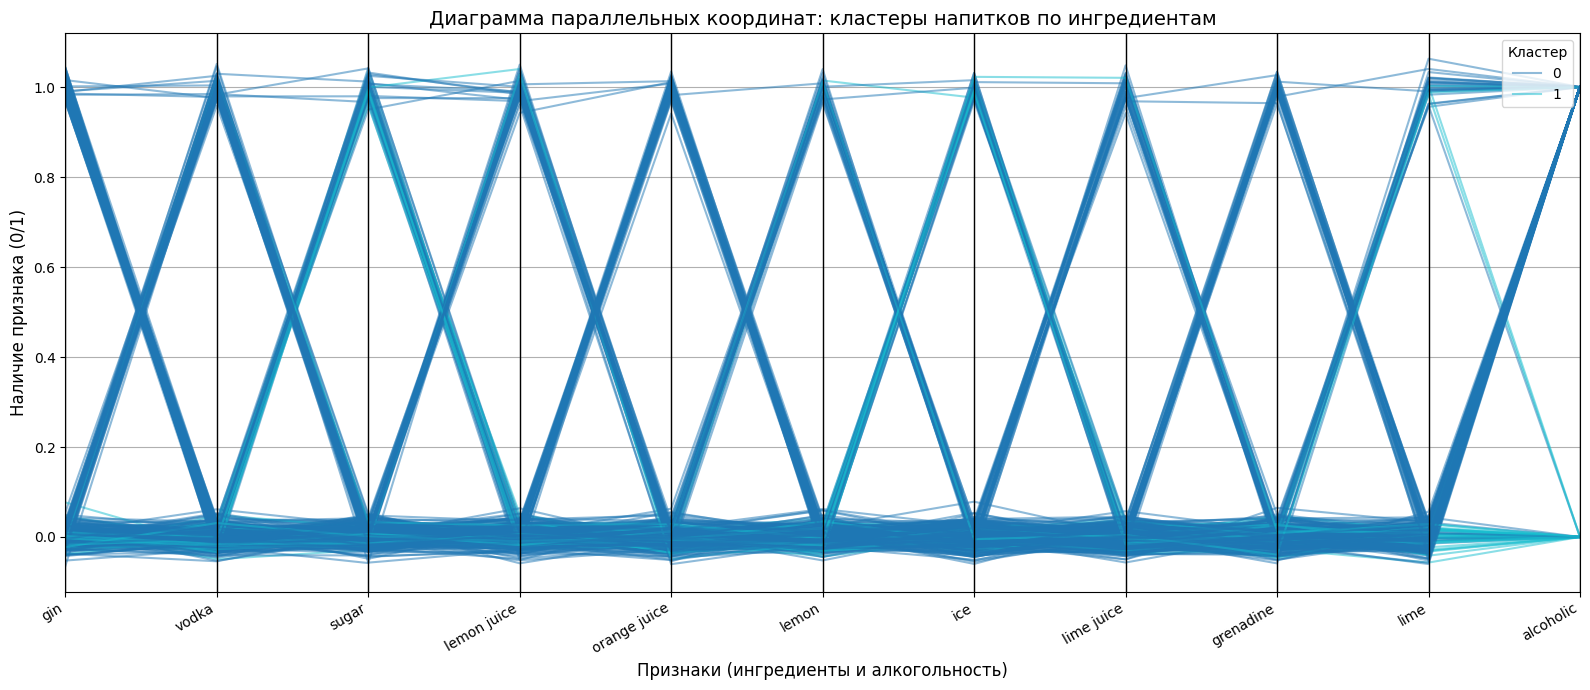

In [12]:
# ============================================================
# 8. ДИАГРАММА ПАРАЛЛЕЛЬНЫХ КООРДИНАТ
# ============================================================
# Параллельные координаты лучше всего работают на компактном наборе
# числовых признаков. Возьмём:
#   - ТОП-10 самых частых ингредиентов (one-hot)
#   - alcoholic_enc
#   - cluster (для окраски)
top_ingredients = [ing for ing, _ in Counter(
    [i for lst in df['ingredients_list'] for i in lst]
).most_common(10)]

# Строим DataFrame с этими признаками
pc_df = pd.DataFrame(X_ing, columns=mlb.classes_)[top_ingredients].copy()
pc_df['alcoholic'] = df['alcoholic_enc'].values
pc_df['cluster'] = df['cluster'].values

# Лёгкое сглаживание (добавляем шум), чтобы точки не сливались на линиях
np.random.seed(42)
for col in top_ingredients:
    pc_df[col] = pc_df[col] + np.random.normal(0, 0.02, size=len(pc_df))

# --- Построение ---
plt.figure(figsize=(16, 7))
parallel_coordinates(
    pc_df,
    class_column='cluster',
    cols=top_ingredients + ['alcoholic'],
    alpha=0.5,
    colormap=plt.get_cmap('tab10')
)
plt.title('Диаграмма параллельных координат: кластеры напитков по ингредиентам',
          fontsize=14)
plt.xlabel('Признаки (ингредиенты и алкогольность)', fontsize=12)
plt.ylabel('Наличие признака (0/1)', fontsize=12)
plt.xticks(rotation=30, ha='right')
plt.legend(title='Кластер', loc='upper right')
plt.tight_layout()
plt.show()

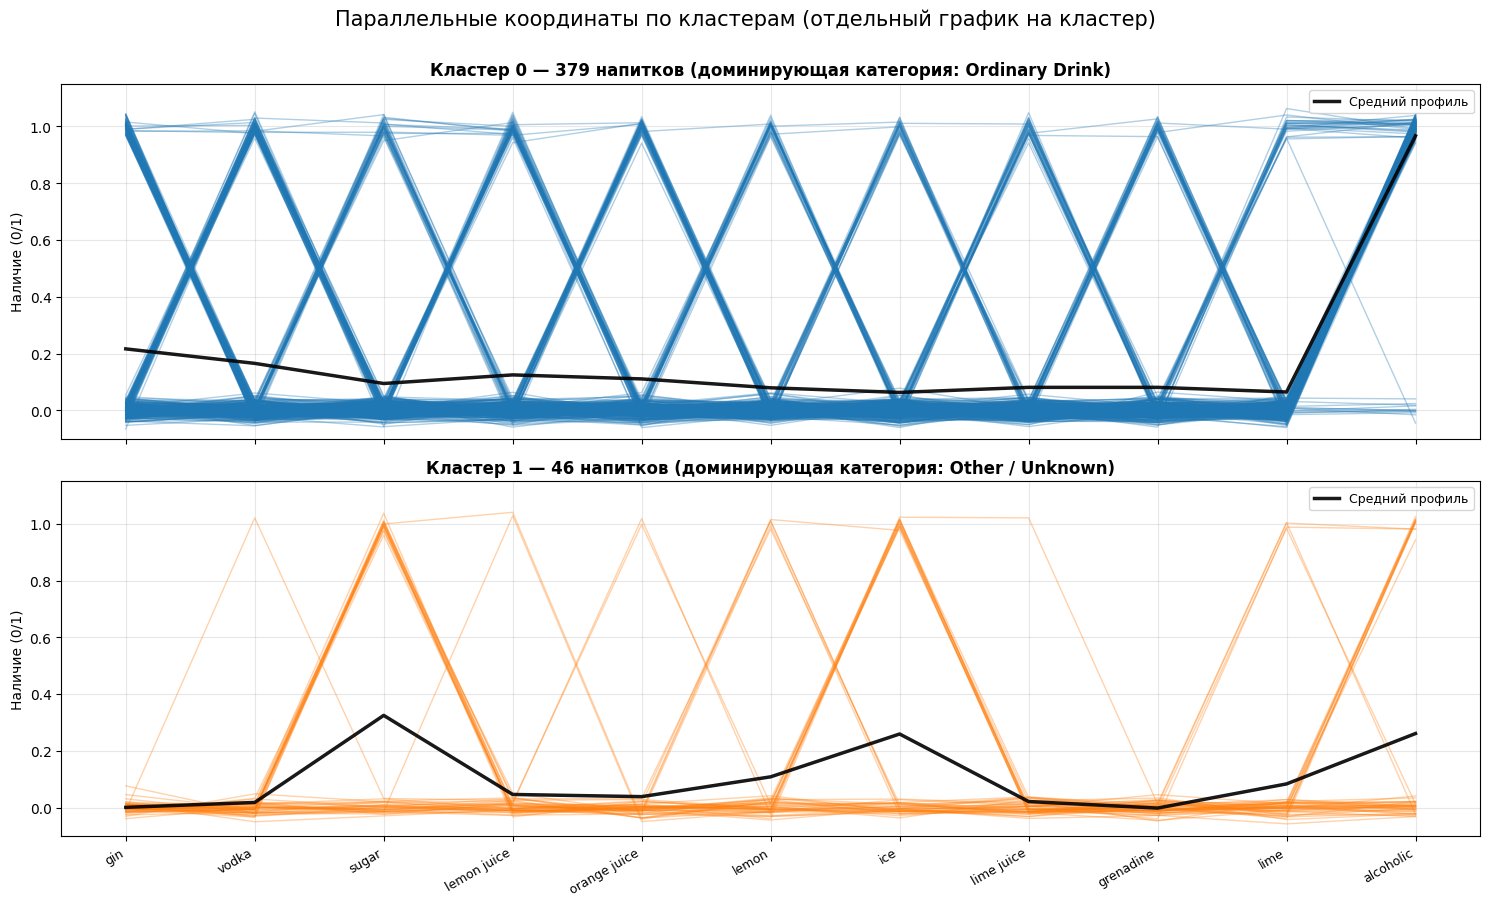

In [13]:
# ============================================================
# 8a. ОТДЕЛЬНАЯ ДИАГРАММА ПАРАЛЛЕЛЬНЫХ КООРДИНАТ ДЛЯ КАЖДОГО КЛАСТЕРА
# ============================================================

# --- Признаки для отображения ---
# Возьмём ТОП-10 ингредиентов по частоте + признак алкогольности
top_ingredients = [ing for ing, _ in Counter(
    [i for lst in df['ingredients_list'] for i in lst]
).most_common(10)]

# Матрица one-hot по ингредиентам (как в шаге 4)
ing_df = pd.DataFrame(X_ing, columns=mlb.classes_)[top_ingredients].copy()
ing_df['alcoholic'] = df['alcoholic_enc'].values
ing_df['cluster'] = df['cluster'].values

# Лёгкий шум, чтобы точки не сливались на горизонтальных линиях
np.random.seed(42)
feature_cols = top_ingredients + ['alcoholic']
for col in feature_cols:
    ing_df[col] = ing_df[col] + np.random.normal(0, 0.02, size=len(ing_df))

# Единый порядок осей для всех графиков — так их можно сравнивать между собой
axis_order = feature_cols

# Единый масштаб Y для всех кластеров — тоже для сопоставимости
y_min, y_max = -0.1, 1.15

clusters = sorted(ing_df['cluster'].unique())
n_clusters = len(clusters)

# --- Сетка графиков: по одному на кластер ---
fig, axes = plt.subplots(n_clusters, 1,
                         figsize=(15, 4.5 * n_clusters),
                         sharex=True)

# Если кластер один — axes не список, приводим к списку
if n_clusters == 1:
    axes = [axes]

# Цвета для каждого кластера (совпадают с tab10 из общей диаграммы)
palette = plt.get_cmap('tab10')

for ax, cl in zip(axes, clusters):
    sub = ing_df[ing_df['cluster'] == cl].copy()
    color = palette(cl % 10)

    # Рисуем каждую строку-напиток как линию
    for _, row in sub.iterrows():
        ax.plot(range(len(axis_order)),
                row[axis_order].values,
                color=color, alpha=0.35, linewidth=1)

    # Средний профиль кластера — жирная линия
    mean_profile = sub[axis_order].mean().values
    ax.plot(range(len(axis_order)),
            mean_profile,
            color='black', linewidth=2.5, alpha=0.9,
            label='Средний профиль')

    # Оформление
    ax.set_xticks(range(len(axis_order)))
    ax.set_xticklabels(axis_order, rotation=30, ha='right', fontsize=9)
    ax.set_ylim(y_min, y_max)
    ax.set_ylabel('Наличие (0/1)', fontsize=10)
    ax.set_title(
        f'Кластер {cl} — {len(sub)} напитков '
        f'(доминирующая категория: {df[df["cluster"]==cl]["category"].mode().iloc[0]})',
        fontsize=12, fontweight='bold'
    )
    ax.legend(loc='upper right', fontsize=9)
    ax.grid(True, alpha=0.3)

plt.suptitle('Параллельные координаты по кластерам (отдельный график на кластер)',
             fontsize=15, y=1.002)
plt.tight_layout()
plt.show()

In [15]:
# ============================================================
# 1. УСТАНОВКА И ИМПОРТЫ
# ============================================================
# Если mlxtend не установлен:
# !pip install mlxtend

import pandas as pd
import numpy as np
import ast
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', 220)
plt.rcParams['figure.figsize'] = (14, 7)
sns.set(style='whitegrid')

In [16]:
# ============================================================
# 2. ЗАГРУЗКА ДАННЫХ И ФОРМИРОВАНИЕ ТРАНЗАКЦИЙ
# ============================================================
df = pd.read_csv('final_cocktails.csv')
if df.columns[0].startswith('Unnamed') or df.columns[0] == '':
    df = df.drop(columns=df.columns[0])

def parse_list(x):
    try:
        return ast.literal_eval(x) if isinstance(x, str) else []
    except (ValueError, SyntaxError):
        return []

df['ingredients_list'] = df['ingredients'].apply(parse_list)
df['ingredients_list'] = df['ingredients_list'].apply(
    lambda lst: [str(i).strip().lower() for i in lst if str(i).strip()]
)
df = df[df['ingredients_list'].map(len) > 0].reset_index(drop=True)

# Каждая строка = «корзина» из ингредиентов одного коктейля
transactions = df['ingredients_list'].tolist()
print("Всего транзакций (коктейлей):", len(transactions))

# Частота ингредиентов
ing_freq = Counter([i for t in transactions for i in t])
print("\nТоп-15 ингредиентов:")
for ing, cnt in ing_freq.most_common(15):
    print(f"  {ing:25s} — {cnt}")

Всего транзакций (коктейлей): 425

Топ-15 ингредиентов:
  gin                       — 82
  vodka                     — 64
  sugar                     — 51
  lemon juice               — 49
  orange juice              — 44
  lemon                     — 40
  ice                       — 36
  lime juice                — 32
  grenadine                 — 31
  lime                      — 30
  light rum                 — 28
  water                     — 28
  powdered sugar            — 26
  triple sec                — 23
  coffee                    — 23


In [17]:
# ============================================================
# 3. One-hot КОДИРОВАНИЕ ТРАНЗАКЦИЙ (basket-формат)
# ============================================================
te = TransactionEncoder()
te_array = te.fit(transactions).transform(transactions)
basket = pd.DataFrame(te_array, columns=te.columns_)

print("Размер basket-матрицы:", basket.shape)
print("Уникальных ингредиентов:", basket.shape[1])
basket.head(3)

Размер basket-матрицы: (425, 293)
Уникальных ингредиентов: 293


,151 proof rum,7-up,absinthe,absolut citron,absolut kurant,absolut peppar,absolut vodka,advocaat,agave syrup,allspice,...,white rum,white wine,wild turkey,wine,worcestershire sauce,wormwood,yellow chartreuse,yoghurt,yukon jack,zima
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [18]:
# ============================================================
# 4. ЧАСТЫЕ НАБОРЫ ИНГРЕДИЕНТОВ (FP-Growth)
# ============================================================
# FP-Growth быстрее Apriori и даёт тот же результат.
MIN_SUPPORT = 0.01  # 1% коктейлей — уже интересно

frequent_itemsets = fpgrowth(
    basket,
    min_support=MIN_SUPPORT,
    use_colnames=True,
    max_len=4          # ограничим длину набора — интерпретируемость
)
frequent_itemsets['length'] = frequent_itemsets['itemsets'].apply(len)
frequent_itemsets = frequent_itemsets.sort_values('support', ascending=False).reset_index(drop=True)

print(f"Найдено частых наборов: {len(frequent_itemsets)}")
print("\nТоп-15 частых наборов:")
display(frequent_itemsets.head(15))

# Распределение по длине набора
print("\nПо длине набора:")
print(frequent_itemsets['length'].value_counts().sort_index())

Найдено частых наборов: 170

Топ-15 частых наборов:


,support,itemsets,length
0,0.192941,frozenset({gin}),1
1,0.150588,frozenset({vodka}),1
2,0.117647,frozenset({sugar}),1
3,0.115294,frozenset({lemon juice}),1
4,0.103529,frozenset({orange juice}),1
5,0.084706,frozenset({ice}),1
6,0.082353,frozenset({lemon}),1
7,0.075294,frozenset({lime juice}),1
8,0.072941,frozenset({grenadine}),1
9,0.068235,frozenset({lime}),1



По длине набора:
length
1    86
2    74
3     9
4     1
Name: count, dtype: int64


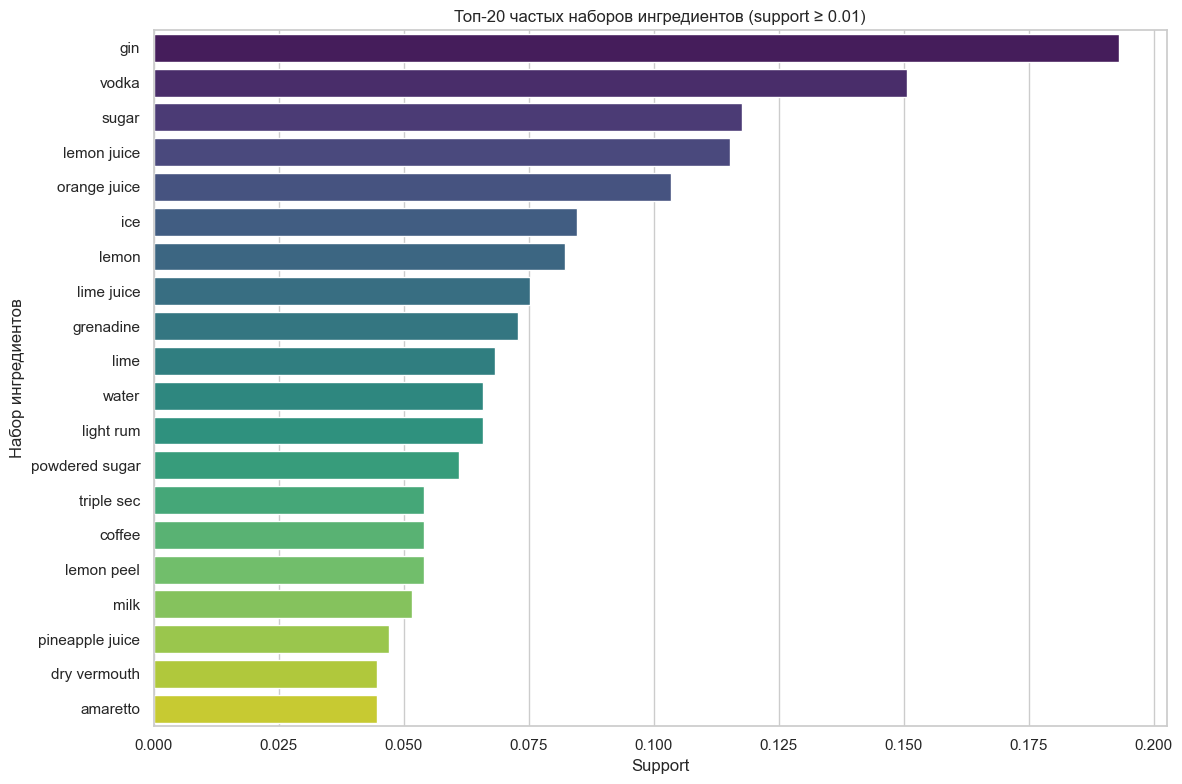

In [19]:
# ============================================================
# 5. ВИЗУАЛИЗАЦИЯ: ТОП-20 ЧАСТЫХ НАБОРОВ
# ============================================================
top_n = 20
top_items = frequent_itemsets.head(top_n).copy()
top_items['label'] = top_items['itemsets'].apply(
    lambda s: ' + '.join(sorted(s))
)

plt.figure(figsize=(12, 8))
sns.barplot(
    data=top_items,
    y='label', x='support',
    palette='viridis',
    hue='label', legend=False
)
plt.title(f'Топ-{top_n} частых наборов ингредиентов (support ≥ {MIN_SUPPORT})')
plt.xlabel('Support')
plt.ylabel('Набор ингредиентов')
plt.tight_layout()
plt.show()

In [20]:
# ============================================================
# 6. АССОЦИАТИВНЫЕ ПРАВИЛА
# ============================================================
MIN_CONFIDENCE = 0.3   # правило должно срабатывать минимум в 30% случаев
MIN_LIFT = 1.2         # lift > 1 — неслучайная связь; > 1.2 — уже интересно

rules = association_rules(
    frequent_itemsets,
    metric='confidence',
    min_threshold=MIN_CONFIDENCE
)

# Фильтр по lift и по длине (для читаемости)
rules = rules[rules['lift'] >= MIN_LIFT].copy()
rules = rules[
    (rules['antecedents'].apply(len) <= 3) &
    (rules['consequents'].apply(len) <= 2)
].reset_index(drop=True)

# Человекочитаемые столбцы
rules['antecedents_str'] = rules['antecedents'].apply(lambda s: ' + '.join(sorted(s)))
rules['consequents_str'] = rules['consequents'].apply(lambda s: ' + '.join(sorted(s)))
rules['rule'] = rules['antecedents_str'] + '  →  ' + rules['consequents_str']

print(f"Всего правил: {len(rules)}")
print("\nТоп-15 правил по lift:")
display(
    rules.sort_values('lift', ascending=False)
         [['rule', 'support', 'confidence', 'lift']]
         .head(15)
         .round(3)
)

Всего правил: 92

Топ-15 правил по lift:


,rule,support,confidence,lift
84,cloves → cinnamon,0.012,0.833,59.028
85,cinnamon → cloves,0.012,0.833,59.028
37,lemon juice + orange → maraschino cherry + sugar,0.014,0.857,52.041
40,maraschino cherry + sugar → lemon juice + orange,0.014,0.857,52.041
39,orange + sugar → lemon juice + maraschino cherry,0.014,0.667,47.222
38,lemon juice + maraschino cherry → orange + sugar,0.014,1.000,47.222
41,maraschino cherry + orange → lemon juice + sugar,0.014,0.857,36.429
36,lemon juice + sugar → maraschino cherry + orange,0.014,0.600,36.429
21,orange → maraschino cherry + sugar,0.016,0.583,35.417
19,maraschino cherry + sugar → orange,0.016,1.000,35.417


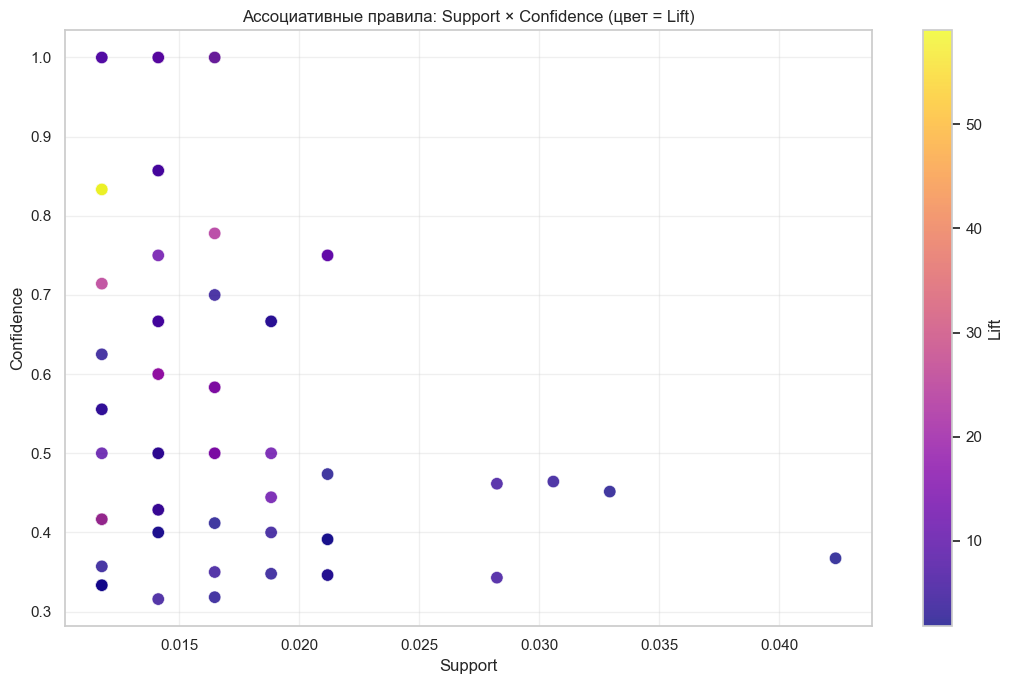

In [21]:
# ============================================================
# 7. SCATTER: SUPPORT × CONFIDENCE, ЦВЕТ = LIFT
# ============================================================
plt.figure(figsize=(11, 7))
sc = plt.scatter(
    rules['support'],
    rules['confidence'],
    c=rules['lift'],
    cmap='plasma',
    s=80,
    alpha=0.8,
    edgecolor='white',
    linewidth=0.5
)
plt.colorbar(sc, label='Lift')
plt.xlabel('Support')
plt.ylabel('Confidence')
plt.title('Ассоциативные правила: Support × Confidence (цвет = Lift)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

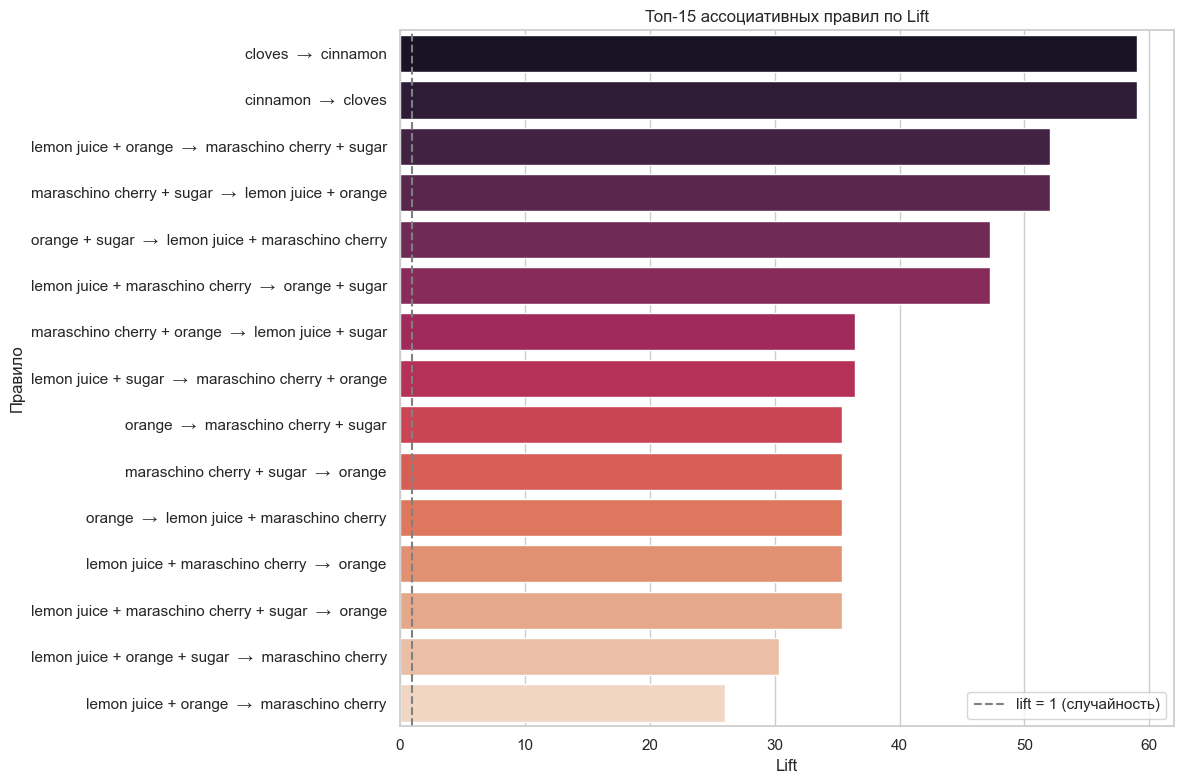

In [22]:
# ============================================================
# 8. ТОП-15 ПРАВИЛ ПО LIFT — ГОРИЗОНТАЛЬНЫЙ БАРЧАРТ
# ============================================================
top_rules = rules.sort_values('lift', ascending=False).head(15)

plt.figure(figsize=(12, 8))
sns.barplot(
    data=top_rules,
    y='rule', x='lift',
    palette='rocket',
    hue='rule', legend=False
)
plt.axvline(1.0, color='gray', linestyle='--', label='lift = 1 (случайность)')
plt.title('Топ-15 ассоциативных правил по Lift')
plt.xlabel('Lift')
plt.ylabel('Правило')
plt.legend()
plt.tight_layout()
plt.show()

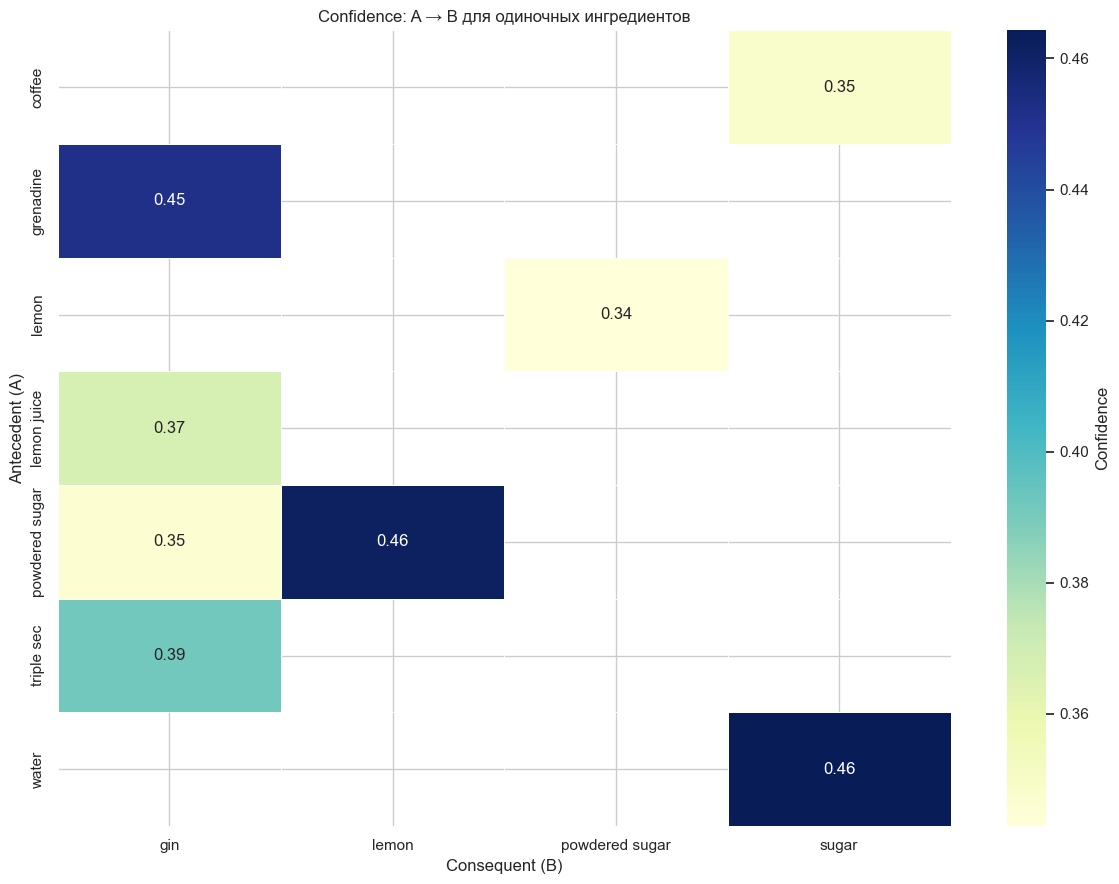

In [23]:
# ============================================================
# 9. HEATMAP: CONFIDENCE МЕЖДУ ОДИНОЧНЫМИ ИНГРЕДИЕНТАМИ
# ============================================================
# Берём только правила вида "1 ингредиент → 1 ингредиент" (самые понятные)
single_rules = rules[
    (rules['antecedents'].apply(len) == 1) &
    (rules['consequents'].apply(len) == 1)
].copy()

single_rules['ant'] = single_rules['antecedents'].apply(lambda s: next(iter(s)))
single_rules['cons'] = single_rules['consequents'].apply(lambda s: next(iter(s)))

# Оставляем топ-15 ингредиентов по частоте
top_ings = [ing for ing, _ in ing_freq.most_common(15)]
matrix = single_rules[
    single_rules['ant'].isin(top_ings) & single_rules['cons'].isin(top_ings)
].pivot_table(index='ant', columns='cons', values='confidence')

plt.figure(figsize=(12, 9))
sns.heatmap(
    matrix,
    annot=True, fmt='.2f',
    cmap='YlGnBu',
    linewidths=0.5,
    cbar_kws={'label': 'Confidence'}
)
plt.title('Confidence: A → B для одиночных ингредиентов')
plt.xlabel('Consequent (B)')
plt.ylabel('Antecedent (A)')
plt.tight_layout()
plt.show()